# 24 — Hasse-Minkowski : le principe local-global calculé

> Série [Serre 100](README.md) — distillation n° 24 · EPIC [#16334](https://github.com/jsboige/CoursIA/issues/16334).
> En amont de ce carnet : [13 — Jacobi, Kronecker, réciprocité II](13-jacobi-kronecker-reciprocite-II.ipynb) calcule les symboles de Legendre-Jacobi employés ici · 22 — Vecteurs de Witt (les fenêtres $\mathbb{Z}/p^k$ que nous rouvrons).

**L'énoncé à rendre calculable** (Serre, *Cours d'arithmétique*, ch. III–IV) :

> **Théorème de Hasse-Minkowski.** Une forme quadratique à coefficients rationnels, en $n \geq 3$ variables, représente $0$ sur $\mathbb{Q}$ si et seulement si elle représente $0$ sur $\mathbb{R}$ **et** sur chaque $\mathbb{Q}_p$.

Une équation diophantienne — objet a priori intractable — devient une **collection finie d'équations sur des corps locaux**, chacune décidable par de l'arithmétique modulaire. Ce carnet fait tourner la machine complète :

1. le **symbole de Hilbert** $(a,b)_v \in \{\pm 1\}$ calculé par les formules fermées de Serre, **validé contre la force brute** $\bmod\ p^k$ ;
2. la **formule du produit** $\prod_v (a,b)_v = +1$ vérifiée sur table ;
3. la décision d'**isotropie locale** place par place (dimensions 1 à 5), validée elle aussi contre la force brute ;
4. le théorème de **Hasse-Minkowski** appliqué à une batterie de formes — chaque verdict porté par une **preuve visible** : un zéro rationnel exhibé, ou la liste exacte des places qui obstruent ;
5. le théorème de **Meyer** (rang $\geq 5$ indéfini) mesuré, puis **la limite du principe** : la cubique de Selmer $3x^3+4y^3+5z^3=0$, localement soluble partout, sans point rationnel.

Chaque affirmation numérique de ce carnet est soit un **témoignage** (un zéro explicitement vérifié), soit une **obstruction** (une place où la forme échoue, ce qui interdit tout zéro rationnel). Rien n'est seulement raconté.

## 1. Le problème : une équation globale, des équations locales

Demandons-nous si

$$x^2 + y^2 + z^2 = 7w^2$$

possède une solution **rationnelle** non triviale. Une recherche directe sur $\mathbb{Q}$ cherche une aiguille dans un tas infini. L'idée de Hasse et Minkowski est de **tester d'abord des conditions nécessaires locales** :

- sur $\mathbb{R}$ : la forme doit être indéfinie — c'est le cas ici ;
- sur chaque $\mathbb{Q}_p$ : l'équation doit avoir une solution $p$-adique, et cela se lit dans une **fenêtre finie** $\mathbb{Z}/p^k$.

Nous avons croisé ces fenêtres au carnet 22 (les vecteurs de Witt vivent dans $\mathbb{Z}/p^k$) ; ici elles servent de **détecteur local**. Le parcours :

| Étape | Objet | Sortie qui prouve |
|---|---|---|
| §2 | valuations, fenêtres $\mathbb{Z}/p^k$ | normalisation des formes |
| §3 | symbole de Hilbert $(a,b)_v$ | formules **vs** force brute, table d'accord |
| §4 | formule du produit | table par paire |
| §5 | isotropie locale (déterminant, invariant de Hasse) | critères **vs** force brute |
| §6 | **Hasse-Minkowski** | zéro exhibé ou places obstructrices |
| §7 | carte d'obstruction $x^2+y^2+z^2=k$ | le théorème des trois carrés **apparaît** |
| §8 | cubique de Selmer | le principe local-global meurt au degré 3 |

In [1]:
from fractions import Fraction
from math import isqrt
import itertools

def vp_int(n, p):
    """Valuation p-adique d'un entier (v(0) = tres grand)."""
    if n == 0:
        return 10**9
    n = abs(n)
    v = 0
    while n % p == 0:
        n //= p
        v += 1
    return v

def vp_frac(x, p):
    """Valuation p-adique d'un rationnel (Fraction)."""
    return vp_int(x.numerator, p) - vp_int(x.denominator, p)

def unit_mod(x, p):
    """Partie unitaire d'un rationnel x (v_p(x) suppose nul), vue mod p (p = 2 : mod 8)."""
    if p == 2:
        return (x.numerator * pow(x.denominator, -1, 8)) % 8
    return (x.numerator % p) * pow(x.denominator % p, -1, p) % p

def entier_mod(x, m):
    """Representant entier mod m d'un rationnel de denominateur premier a m."""
    return (x.numerator % m) * pow(x.denominator % m, -1, m) % m

print("Helpers charges. Exemple : v_3(18/10) =", vp_frac(Fraction(18, 10), 3))

Helpers charges. Exemple : v_3(18/10) = 2


## 2. Fenêtres $\mathbb{Z}/p^k$ et normalisation des formes

Une forme diagonale $q = \langle c_1, \dots, c_n \rangle$ désigne $q(x) = \sum_i c_i x_i^2$. Trois gestes gratuits s'appliquent avant tout calcul local en $p$ :

1. **échelle** : multiplier $q$ par $\lambda \neq 0$ ne change pas son isotropie ;
2. **carrés** : multiplier **un** coefficient par un carré revient à changer la variable correspondante ($x_i \mapsto x_i / p$ pour un facteur $p^2$) — la classe d'isomorphisme sur $\mathbb{Q}_p$ ne change pas ;
3. **normalisation** : on descend à des coefficients $p$-entiers avec $\min_i v_p(c_i) = 0$.

Pour une forme normalisée, l'isotropie sur $\mathbb{Q}_p$ se détecte dans une fenêtre finie : un zéro **primitif** (un vecteur $x$ dont une coordonnée n'est pas divisible par $p$) modulo $p^2$ pour $p$ impair, modulo $2^6$ pour $p = 2$. Hensel relève le zéro lisse en un zéro exact dans $\mathbb{Z}_p$ ; réciproquement un zéro $p$-adique se réduit en zéro primitif de toute fenêtre. La profondeur 3 en $p = 2$ ne suffit pas : $\langle 1, 2, -10 \rangle$ possède le zéro primitif $(0,1,1)$ modulo 8 — car $q(0,1,1) = -8$ — alors qu'elle est anisotrope sur $\mathbb{Q}_2$ ; le même vecteur échoue modulo 16 et au-delà. C'est ce qui fait de la force brute modulaire une **sonde honnête** du monde $p$-adique, à condition de choisir sa profondeur — nous y reviendrons à chaque validation.

## 3. Le symbole de Hilbert $(a,b)_v$

**Définition** (Serre, ch. III, §1.1). Pour $a, b \in \mathbb{Q}_v^*$ :

$$(a,b)_v = \begin{cases} +1 & \text{si } ax^2 + by^2 = 1 \text{ a une solution dans } \mathbb{Q}_v, \\ -1 & \text{sinon.} \end{cases}$$

C'est le **témoin local élémentaire** : il code si le plan $\langle a, b \rangle$ représente 1. Trois formules fermées le calculent :

- **$v = \infty$** : $(a,b)_\infty = -1$ si et seulement si $a < 0$ et $b < 0$ ;
- **$p$ impair**, avec $a = p^\alpha u$, $b = p^\beta v$ ($u, v$ unités) :
  $$(a,b)_p = (-1)^{\alpha\beta\,\frac{p-1}{2}} \left(\frac{u}{p}\right)^{\!\beta} \left(\frac{v}{p}\right)^{\!\alpha} ;$$
- **$p = 2$**, avec $\varepsilon(u) = \frac{u-1}{2} \bmod 2$ et $\omega(u) = \frac{u^2-1}{8} \bmod 2$ :
  $$(a,b)_2 = (-1)^{\varepsilon(u)\varepsilon(v) + \alpha\,\omega(v) + \beta\,\omega(u)} .$$

Nous implémentons les trois, **puis nous les confrontons à un oracle indépendant**. Le théorème 6′ de Serre (ch. IV) donne le pont : $(a,b)_v = +1$ si et seulement si la forme ternaire $\langle 1, -a, -b\rangle$ possède un **zéro primitif** dans la fenêtre $\bmod\ p^2$ ($p$ impair) ou $\bmod\ 2^6$ ($p = 2$, cf. §2 sur la profondeur). Chercher $ax^2+by^2=1$ directement sur des entiers serait un oracle trompeur — les solutions rationnelles à dénominateurs (comme $x=y=\tfrac14$ pour $(2,14)_2$) lui échappent ; le zéro primitif ternaire les voit toutes. L'accord des deux colonnes est la preuve que les formules font ce qu'elles annoncent.

In [2]:
def legendre(a, p):
    """Symbole de Legendre (a/p) pour p premier impair : -1, 0 ou +1."""
    a %= p
    if a == 0:
        return 0
    r = pow(a, (p - 1) // 2, p)
    return -1 if r == p - 1 else 1

def hilbert_infini(a, b):
    """(a,b) sur R : -1 ssi les deux sont negatifs."""
    return -1 if (a < 0 and b < 0) else 1

def hilbert_p_impair(a, b, p):
    """(a,b)_p pour p impair, formule de Serre ch. III. a, b : Fraction."""
    va, vb = vp_frac(a, p), vp_frac(b, p)
    alpha, beta = va % 2, vb % 2
    u, v = a * Fraction(p) ** (-va), b * Fraction(p) ** (-vb)   # parties unitaires
    signe = (-1) ** ((alpha * beta * ((p - 1) // 2)) % 2)
    return signe * legendre(unit_mod(u, p), p) ** beta * legendre(unit_mod(v, p), p) ** alpha

def _eps_2(u):
    return ((u - 1) // 2) % 2

def _omega_2(u):
    return ((u * u - 1) // 8) % 2

def hilbert_2(a, b):
    """(a,b)_2 par la table des huit classes de unites."""
    va, vb = vp_frac(a, 2), vp_frac(b, 2)
    alpha, beta = va % 2, vb % 2
    u, v = a * Fraction(2) ** (-va), b * Fraction(2) ** (-vb)
    u8, v8 = unit_mod(u, 2), unit_mod(v, 2)    # unites impaires vues mod 8
    exposant = _eps_2(u8) * _eps_2(v8) + alpha * _omega_2(v8) + beta * _omega_2(u8)
    return -1 if exposant % 2 else 1

def hilbert(a, b, v):
    """Symbole de Hilbert (a,b)_v. v = 'inf' ou nombre premier. a, b : Fraction."""
    if v == 'inf':
        return hilbert_infini(a, b)
    if v == 2:
        return hilbert_2(a, b)
    return hilbert_p_impair(a, b, v)

print("Valeurs canoniques :")
print("  (-1,-1)_inf =", hilbert(Fraction(-1), Fraction(-1), 'inf'), " (attendu -1 : les deux negatifs)")
print("  (-1,-1)_2   =", hilbert(Fraction(-1), Fraction(-1), 2), " (attendu -1 : Hamilton)")
print("  (3,5)_7     =", hilbert(Fraction(3), Fraction(5), 7))

Valeurs canoniques :
  (-1,-1)_inf = -1  (attendu -1 : les deux negatifs)
  (-1,-1)_2   = -1  (attendu -1 : Hamilton)
  (3,5)_7     = 1


In [3]:
def forme_entiere_normalisee(cs, p):
    """Coefficients entiers, carres p^2 retires, min valuation p-adique 0."""
    from math import gcd
    den = 1
    for c in cs:
        den *= c.denominator
    ints = [int(c * den) for c in cs]
    g = 0
    for t in ints:
        g = gcd(g, abs(t))
    if g > 1:
        ints = [t // g for t in ints]
    changed = True
    while changed:
        changed = False
        if min(vp_int(t, p) for t in ints) >= 2:
            ints = [t // p // p for t in ints]
            changed = True
            continue
        for i, t in enumerate(ints):
            if vp_int(t, p) >= 2:
                ints[i] = t // p // p
                changed = True
    return ints

def zero_primitif_brut(cs, m, p):
    """La forme diagonale entiere cs a-t-elle un zero primitif mod m ?
    Rencontre de sommes sur les deux moities de variables ; primitif = une coordonnee non divisible par p."""
    n = len(cs)
    h1, h2 = list(range(n // 2)), list(range(n // 2, n))
    table = {}
    for combo in itertools.product(range(m), repeat=len(h2)):
        s = sum(cs[i] * x * x for i, x in zip(h2, combo)) % m
        table.setdefault(s, []).append(combo)
    for combo1 in itertools.product(range(m), repeat=len(h1)):
        s1 = sum(cs[i] * x * x for i, x in zip(h1, combo1)) % m
        for combo2 in table.get((-s1) % m, []):
            vec = [0] * n
            for i, x in zip(h1, combo1):
                vec[i] = x
            for i, x in zip(h2, combo2):
                vec[i] = x
            if any(x % p for x in vec):
                return True
    return False

def symbole_brut(a, b, p, k):
    """Oracle independant (Serre th. 6') : (a,b)_p = +1 ssi <1,-a,-b> a un zero primitif mod p^k.
    Une equation d'entiers, pas de solutions rationnelles a denominateurs a chercher."""
    cs = forme_entiere_normalisee([Fraction(1), Fraction(-a), Fraction(-b)], p)
    return zero_primitif_brut(cs, p ** k, p)

# --- validation p impairs : formule contre oracle ternaire mod p^2 ---
print("Validation (a,b)_p : formule de Serre contre zero primitif de <1,-a,-b> mod p^2")
print(f"{'p':>3} {'p^2':>4}  tests  desaccords")
totaux, desaccords = 0, 0
for p in [3, 5, 7, 11]:
    for a in [-6, -5, -3, -1, 1, 2, 3, 6, 10, p, -p]:
        for b in [-6, -1, 1, 2, 3, 5, 7, 12, p]:
            totaux += 1
            if (hilbert(Fraction(a), Fraction(b), p) == 1) != symbole_brut(a, b, p, 2):
                desaccords += 1
                print(f"  MISMATCH a={a} b={b} p={p}")
    print(f"{p:>3} {p * p:>4}  (cumul {totaux})  {desaccords}")
print("p impairs :", totaux, "tests,", desaccords, "desaccords ->",
      "ACCORD TOTAL" if desaccords == 0 else "A REPARER")

Validation (a,b)_p : formule de Serre contre zero primitif de <1,-a,-b> mod p^2
  p  p^2  tests  desaccords
  3    9  (cumul 99)  0
  5   25  (cumul 198)  0


  7   49  (cumul 297)  0


 11  121  (cumul 396)  0
p impairs : 396 tests, 0 desaccords -> ACCORD TOTAL


In [4]:
# --- validation p = 2 : la table des huit classes contre oracle ternaire mod 8 ---
print("Validation (a,b)_2 : formule contre zero primitif de <1,-a,-b> mod 2^6")
totaux2, desaccords2 = 0, 0
for a in [-8, -6, -5, -3, -2, -1, 1, 2, 3, 5, 6, 10, 18, 24]:
    for b in [-3, -1, 1, 2, 3, 5, 7, 10, 14]:
        totaux2 += 1
        if (hilbert(Fraction(a), Fraction(b), 2) == 1) != symbole_brut(a, b, 2, 6):
            desaccords2 += 1
            print(f"  MISMATCH a={a} b={b}: formule={hilbert(Fraction(a), Fraction(b), 2)}")
print("p = 2 :", totaux2, "tests,", desaccords2, "desaccords ->",
      "ACCORD TOTAL" if desaccords2 == 0 else "A REPARER")

Validation (a,b)_2 : formule contre zero primitif de <1,-a,-b> mod 2^6


p = 2 : 126 tests, 0 desaccords -> ACCORD TOTAL


Les formules et la force brute **rendent le même verdict sur la totalité des tests** — aucune ligne `MISMATCH`. Le symbole de Hilbert est désormais un objet de calcul fiable : une ligne de code par place.

## 4. La formule du produit

**Théorème** (Serre, ch. III, §3). Pour $a, b \in \mathbb{Q}^*$ :

$$\prod_{v \in \{\infty, 2, 3, 5, \dots\}} (a,b)_v = +1 .$$

Le produit porte sur **toutes** les places, mais seuls $v = \infty$, $v = 2$ et les $p$ divisant $ab$ peuvent contribuer $-1$ : la table est finie. C'est le premier théorème global que la machine vérifie.

In [5]:
def places_pertinentes(a, b):
    """Places ou (a,b)_v peut valoir -1 : inf, 2, et les premiers divisant ab."""
    n = abs(a.numerator * a.denominator * b.numerator * b.denominator)
    ps = {2}
    d = 2
    while d * d <= n:
        while n % d == 0:
            ps.add(d)
            n //= d
        d += 1
    if n > 1:
        ps.add(n)
    return ['inf'] + sorted(ps)

def produit_hilbert(a, b):
    vals = {}
    for v in places_pertinentes(Fraction(a), Fraction(b)):
        vals[v] = hilbert(Fraction(a), Fraction(b), v)
    prod = 1
    for s in vals.values():
        prod *= s
    return prod, vals

print(f"{'a':>4} {'b':>4}  places a -1                     produit")
tous_ok = True
for a, b in [(-1, -1), (-1, 3), (2, 3), (5, 7), (-6, 10), (3, 5), (-1, 2), (12, 18), (-5, 13), (7, 30)]:
    prod, vals = produit_hilbert(Fraction(a), Fraction(b))
    lieux = [str(v) for v, s in vals.items() if s == -1] or ["(aucune)"]
    tous_ok = tous_ok and prod == 1
    print(f"{a:>4} {b:>4}  {', '.join(lieux):<30} {prod:+d}")
print("\nProduits tous egaux a +1 :", tous_ok, "- les -1 vont par paires de places.")

   a    b  places a -1                     produit
  -1   -1  inf, 2                         +1
  -1    3  2, 3                           +1
   2    3  2, 3                           +1
   5    7  5, 7                           +1
  -6   10  (aucune)                       +1
   3    5  3, 5                           +1
  -1    2  (aucune)                       +1
  12   18  2, 3                           +1
  -5   13  5, 13                          +1
   7   30  2, 5                           +1

Produits tous egaux a +1 : True - les -1 vont par paires de places.


Chaque ligne rend $+1$ : un $-1$ quelque part **force** un autre $-1$ ailleurs. Premier phénomène global émergent d'un calcul purement local.

## 5. Isotropie locale : déterminant et invariant de Hasse

Deux invariants d'une forme diagonale $q = \langle c_1, \dots, c_n \rangle$ en chaque place :

- le **déterminant** $d = c_1 c_2 \cdots c_n$, vu **modulo les carrés** de $\mathbb{Q}_v$ ;
- l'**invariant de Hasse** $\varepsilon_v = \prod_{i < j} (c_i, c_j)_v \in \{\pm 1\}$.

Critères d'isotropie locale (Serre, ch. IV ; le point clé pour $n = 4$ : sur chaque $\mathbb{Q}_p$ il n'existe, à similarité près, **qu'une seule** forme quaternaire anisotrope — la norme de l'algèbre de quaternions division — dont le déterminant est un carré et l'invariant de Hasse vaut $-1$ si $p$ est impair, $+1$ si $p = 2$) :

| $n$ | $q$ isotrope sur $\mathbb{Q}_v$ ssi |
|---|---|
| 1 | jamais (forme non nulle) |
| 2 | $-c_1 c_2$ est un carré dans $\mathbb{Q}_v$ |
| 3 | $\left(-c_2/c_1,\; -c_3/c_1\right)_v = +1$ (Serre, th. 6′ : $\langle 1,-a,-b\rangle$ isotrope $\Leftrightarrow (a,b)=1$) |
| 4, $v$ finie | **non**($d$ carré et $\varepsilon_v = \varepsilon^{\text{aniso}}_v$), avec $\varepsilon^{\text{aniso}}_p = -1$ ($p$ impair), $+1$ ($p=2$) |
| 4, $\infty$ ; $n \geq 5$, $\infty$ | forme indéfinie |
| $\geq 5$, $v$ finie | toujours (l'invariant de Brauer $u(\mathbb{Q}_p) = 4$) |

Le critère $n = 4$ est celui qu'une mémoire défaillaste gâterait : nous ne le croyons pas sur parole — **la cellule suivante le confronte à la force brute**, comme les symboles en §3.

In [6]:
def est_carre_Qp(x, v):
    """x (Fraction) est-il un carre dans Q_v ?"""
    if v == 'inf':
        return x >= 0
    val = vp_frac(x, v)
    if val % 2:
        return False
    u = x * Fraction(v) ** (-val)
    if v == 2:
        return unit_mod(u, 2) == 1
    return legendre(unit_mod(u, v), v) == 1

def invariant_hasse(cs, v):
    eps = 1
    for i in range(len(cs)):
        for j in range(i + 1, len(cs)):
            eps *= hilbert(cs[i], cs[j], v)
    return eps

EPS_ANISO = {True: 1, False: -1}   # cle : (v == 2)

def isotrope_local(cs, v):
    """q = <c1..cn> (Fractions) est-elle isotrope sur Q_v ?"""
    n = len(cs)
    if v == 'inf':
        return any(c > 0 for c in cs) and any(c < 0 for c in cs)
    if n == 1:
        return False
    if n == 2:
        return est_carre_Qp(-cs[0] * cs[1], v)
    if n == 3:
        return hilbert(-cs[1] / cs[0], -cs[2] / cs[0], v) == 1
    if n == 4:
        d = cs[0] * cs[1] * cs[2] * cs[3]
        aniso = est_carre_Qp(d, v) and invariant_hasse(cs, v) == EPS_ANISO[v == 2]
        return not aniso
    return True   # n >= 5, place finie

# --- validation des criteres locaux contre l'oracle de zero primitif (fonctions en §3) ---
print("Validation des criteres locaux (n = 3, 4) contre force brute (zéro primitif) :")
import random
random.seed(20261025)
CHOIX = [-5, -3, -2, -1, 1, 2, 3, 5, 7]
totaux, desaccords = 0, 0
for p, k, dims in [(3, 2, [3, 4]), (5, 2, [3, 4]), (7, 2, [3, 4]), (11, 2, [3]), (13, 2, [3]), (2, 6, [3, 4])]:
    m = p ** k
    for _ in range(30):
        n = random.choice(dims)
        cs = [Fraction(random.choice(CHOIX)) for _ in range(n)]
        ints = forme_entiere_normalisee(cs, p)
        brute = zero_primitif_brut(ints, m, p)
        critere = isotrope_local(cs, p)
        totaux += 1
        if brute != critere:
            desaccords += 1
            if desaccords <= 6:
                print(f"  MISMATCH p={p} cs={ints}: critere={critere} brute={brute}")
print(totaux, "formes aleatoires testees,", desaccords, "desaccords ->",
      "ACCORD TOTAL" if desaccords == 0 else "A REPARER")

Validation des criteres locaux (n = 3, 4) contre force brute (zéro primitif) :


180 formes aleatoires testees, 0 desaccords -> ACCORD TOTAL


Les critères des dimensions 3 et 4 passent l'épreuve de la force brute sur 180 formes aléatoires. L'oracle local est complet et auto-vérifié.

## 6. Hasse-Minkowski : la décision globale, preuve à l'appui

Le théorème dit que pour $n \geq 3$, l'isotropie globale équivaut à l'isotropie **partout** — et seules les places $\infty$, $2$ et les premiers divisant les coefficients peuvent obstructer (en $n \geq 3$, une forme unimodulaire en $p \nmid 2\prod c_i$ est isotrope : Chevalley-Warning). La fonction ci-dessous rend son verdict **avec sa preuve** :

- forme isotrope → elle **exhibe un zéro rationnel** (recherche bornée par rencontre de sommes) et le re-vérifie ;
- sinon → elle **liste les places obstructrices**, chacune étant un certificat d'impossibilité (un zéro rationnel donnerait un zéro dans toute complétion).

In [7]:
def places_forme(cs):
    n = abs(cs[0].numerator * cs[0].denominator)
    for c in cs[1:]:
        n = abs(n * c.numerator * c.denominator)
    ps = {2}
    d = 2
    while d * d <= n:
        while n % d == 0:
            ps.add(d)
            n //= d
        d += 1
    if n > 1:
        ps.add(n)
    return ['inf'] + sorted(x for x in ps if x > 1)

def est_carre_rationnel(x):
    x = Fraction(x)
    if x < 0:
        return False
    rn, rd = isqrt(x.numerator), isqrt(x.denominator)
    return rn * rn == x.numerator and rd * rd == x.denominator

def trouver_zero(cs, N=40):
    """Recherche bornee d'un zero rationnel (denominateurs libres, borne |numerateur| <= N)
    par rencontre de sommes : table de la premiere moitie, balayage de la seconde."""
    n = len(cs)
    h1, h2 = list(range(n // 2)), list(range(n // 2, n))
    table = {}
    for combo in itertools.product(range(-N, N + 1), repeat=len(h1)):
        s = sum(cs[i] * x * x for i, x in zip(h1, combo))
        table.setdefault(s, combo)
    for combo2 in itertools.product(range(-N, N + 1), repeat=len(h2)):
        s2 = sum(cs[i] * x * x for i, x in zip(h2, combo2))
        if -s2 in table:
            vec = [0] * n
            for i, x in zip(h1, table[-s2]):
                vec[i] = x
            for i, x in zip(h2, combo2):
                vec[i] = x
            if any(v != 0 for v in vec):
                # temoin reduit : pgcd des numerateurs, premier non nul positif
                from math import gcd
                g = 0
                for v in vec:
                    g = gcd(g, abs(v))
                vec = [v // g for v in vec]
                if next(v for v in vec if v) < 0:
                    vec = [-v for v in vec]
                return [Fraction(v) for v in vec]
    return None

def verifier_zero(cs, zero):
    return (sum(c * x * x for c, x in zip(cs, zero)) == 0
            and any(x != 0 for x in zero))

def isotrope_global(cs):
    """Verdict global + certificat (zero exhibe ou places obstructrices)."""
    n = len(cs)
    if n == 1:
        return False, {"obstructions": ["(rang 1 : jamais isotrope)"]}
    if n == 2:
        if est_carre_rationnel(-cs[0] * cs[1]):
            return True, {"zero": trouver_zero(cs)}
        return False, {"obstructions": ["(binaire : -c1c2 n'est pas un carre dans Q)"]}
    obstructions = [v for v in places_forme(cs) if not isotrope_local(cs, v)]
    if obstructions:
        return False, {"obstructions": obstructions}
    return True, {"zero": trouver_zero(cs)}

BATTERIE = [
    ("<1,1,1,-1>", [Fraction(1)] * 3 + [Fraction(-1)]),
    ("<1,1,1,-3>", [Fraction(1)] * 3 + [Fraction(-3)]),
    ("<1,1,1,-7>", [Fraction(1)] * 3 + [Fraction(-7)]),
    ("<1,1,1,1>  (norme hamiltonienne)", [Fraction(1)] * 4),
    ("<1,1,-3>  (x^2+y^2=3z^2)", [Fraction(1), Fraction(1), Fraction(-3)]),
    ("<1,1,-2,-3>", [Fraction(1), Fraction(1), Fraction(-2), Fraction(-3)]),
    ("<2,3,-5>", [Fraction(2), Fraction(3), Fraction(-5)]),
    ("<1,1,1,1,-7>  (Meyer, rang 5)", [Fraction(1)] * 4 + [Fraction(-7)]),
    ("<1,1,1,1,-23>  (Meyer, rang 5)", [Fraction(1)] * 4 + [Fraction(-23)]),
]
print(f"{'forme':<36} {'verdict':<12} certificat")
for nom, cs in BATTERIE:
    ok, cert = isotrope_global(cs)
    if ok and cert.get('zero') is not None:
        z = cert['zero']
        preuve = f"zero rationnel {[str(t) for t in z]} (re-verifie : {verifier_zero(cs, z)})"
        verdict = "ISOTROPE"
    elif ok:
        preuve = "isotrope (zero hors borne de recherche)"
        verdict = "ISOTROPE"
    else:
        preuve = f"obstructions : {cert['obstructions']}"
        verdict = "ANISOTROPE"
    print(f"{nom:<36} {verdict:<12} {preuve}")

forme                                verdict      certificat
<1,1,1,-1>                           ISOTROPE     zero rationnel ['0', '0', '1', '1'] (re-verifie : True)
<1,1,1,-3>                           ISOTROPE     zero rationnel ['1', '1', '1', '1'] (re-verifie : True)
<1,1,1,-7>                           ANISOTROPE   obstructions : [2]
<1,1,1,1>  (norme hamiltonienne)     ANISOTROPE   obstructions : ['inf', 2]
<1,1,-3>  (x^2+y^2=3z^2)             ANISOTROPE   obstructions : [2, 3]


<1,1,-2,-3>                          ISOTROPE     zero rationnel ['1', '1', '1', '0'] (re-verifie : True)
<2,3,-5>                             ISOTROPE     zero rationnel ['1', '1', '1'] (re-verifie : True)


<1,1,1,1,-7>  (Meyer, rang 5)        ISOTROPE     zero rationnel ['3', '2', '5', '5', '3'] (re-verifie : True)
<1,1,1,1,-23>  (Meyer, rang 5)       ISOTROPE     zero rationnel ['5', '1', '10', '9', '3'] (re-verifie : True)


### Lecture des résultats

- Chaque forme **isotrope** vient avec un zéro rationnel **numérique et re-vérifié**, réduit à son plus petit multiple entier — la preuve est le point lui-même : $(1,1,1,1)$ pour $x^2+y^2+z^2=3w^2$, $(1,1,1,0)$ pour $\langle 1,1,-2,-3\rangle$ (c'est $1+1=2$), $(1,1,1)$ pour $2x^2+3y^2=5z^2$.
- $\langle 1,1,1,-7 \rangle$ est **anisotrope** : l'obstruction est portée par la seule place $2$ — car $7 \equiv -1 \bmod 8$, et trois carrés 2-adiques ne peuvent pas sommer à $7w^2$. C'est exactement la ligne $7 = 4^0(8\cdot0+7)$ du théorème des trois carrés de Legendre–Gauss (§8).
- $\langle 1,1,1,1 \rangle$, la norme des quaternions d'Hamilton, est anisotrope : obstructée en $\infty$ (définie positive) **et** en $2$ — le double $-1$ que la formule du produit (§4) imposait déjà pour $a = b = -1$.
- $\langle 1,1,-3\rangle$ : l'équation $x^2 + y^2 = 3z^2$ échoue en $2$ **et** en $3$ — une obstruction répartie sur deux places, exactement en nombre pair, comme l'exige la formule du produit.

**Le point méthodologique** : aucun verdict n'est une autorité citée. Chaque « isotrope » est un point exhibé ; chaque « anisotrope » est une place où l'échec est lui-même calculé (§3–§5 validés par force brute). Le théorème de Hasse-Minkowski n'intervient que pour garantir que la liste des places testées est **exhaustive** : c'est son rôle — transformer une collection de certificats locaux en décision globale.

## 7. Meyer : au rang 5, l'indéfini l'emporte toujours

**Théorème de Meyer** (Serre, ch. IV, th. 8) : toute forme quadratique **indéfinie** de rang $\geq 5$ sur $\mathbb{Q}$ est isotrope. Nos critères le lisent mécaniquement : en rang 5, aucune place finie n'obstructe ($u(\mathbb{Q}_p) = 4$), seule $\infty$ peut — et $\infty$ n'obstructe que les formes définies.

In [8]:
print("Meyer en action : <1,1,1,1,-k> (k choisi parmi les non-sommes de 3 carres)")
print("aux rangs 3-4, la machine retrouve des zeros qu'aucune somme de 3 carres ne donne :")
for k in [7, 15, 23, 31, 39, 55]:
    cs = [Fraction(1)] * 4 + [Fraction(-k)]
    ok, cert = isotrope_global(cs)
    z = cert.get('zero')
    if z is not None and verifier_zero(cs, z):
        detail = " + ".join(f"{ci}·({zi})²" for ci, zi in zip(cs, z) if zi != 0)
        print(f"  k = {k:>3} : ISOTROPE, temoin {[str(t) for t in z]}  ({detail} = 0)")
    else:
        print(f"  k = {k:>3} : verdict inattendu ({ok}, zero={z})")

cs_def = [Fraction(1)] * 5
ok, cert = isotrope_global(cs_def)
print(f"  <1,1,1,1,1> definie : verdict={ok}, obstructions={cert.get('obstructions')} (seule inf peut bloquer en rang 5)")

Meyer en action : <1,1,1,1,-k> (k choisi parmi les non-sommes de 3 carres)
aux rangs 3-4, la machine retrouve des zeros qu'aucune somme de 3 carres ne donne :


  k =   7 : ISOTROPE, temoin ['3', '2', '5', '5', '3']  (1·(3)² + 1·(2)² + 1·(5)² + 1·(5)² + -7·(3)² = 0)
  k =  15 : ISOTROPE, temoin ['3', '1', '5', '5', '2']  (1·(3)² + 1·(1)² + 1·(5)² + 1·(5)² + -15·(2)² = 0)


  k =  23 : ISOTROPE, temoin ['5', '1', '10', '9', '3']  (1·(5)² + 1·(1)² + 1·(10)² + 1·(9)² + -23·(3)² = 0)


  k =  31 : ISOTROPE, temoin ['7', '7', '10', '9', '3']  (1·(7)² + 1·(7)² + 1·(10)² + 1·(9)² + -31·(3)² = 0)
  k =  39 : ISOTROPE, temoin ['2', '1', '5', '3', '1']  (1·(2)² + 1·(1)² + 1·(5)² + 1·(3)² + -39·(1)² = 0)
  k =  55 : ISOTROPE, temoin ['2', '1', '5', '5', '1']  (1·(2)² + 1·(1)² + 1·(5)² + 1·(5)² + -55·(1)² = 0)
  <1,1,1,1,1> definie : verdict=False, obstructions=['inf'] (seule inf peut bloquer en rang 5)


## 8. La carte d'obstruction : le théorème des trois carrés **apparaît**

Appliquons la machine à toute la famille quaternaire $q_k = \langle 1,1,1,-k \rangle$ (l'équation $x^2+y^2+z^2 = k\,w^2$) pour $1 \leq k \leq 48$, et dessinons **quelle place obstructe quel $k$**. Le théorème des trois carrés de Legendre–Gauss — $k$ est somme de trois carrés ssi $k \neq 4^a(8b+7)$ — n'est **pas codé** : il doit **émerger** de la carte locale. Or nos critères le prédisent : pour cette famille, $\varepsilon_v \equiv 1$ partout, le déterminant est $-k$, et $-k$ n'est un carré 2-adique que pour $k = 4^a(8b+7)$ — aucune place impaire ne peut obstructer (déterminant de valuation impaire ou invariant de Hasse fautif), $\infty$ non plus (indéfinie).

Accord carte locale <-> critere de Legendre-Gauss sur k = 1..48 : True
k non sommes de 3 carres, predits par la seule carte locale : [7, 15, 23, 28, 31, 39, 47]


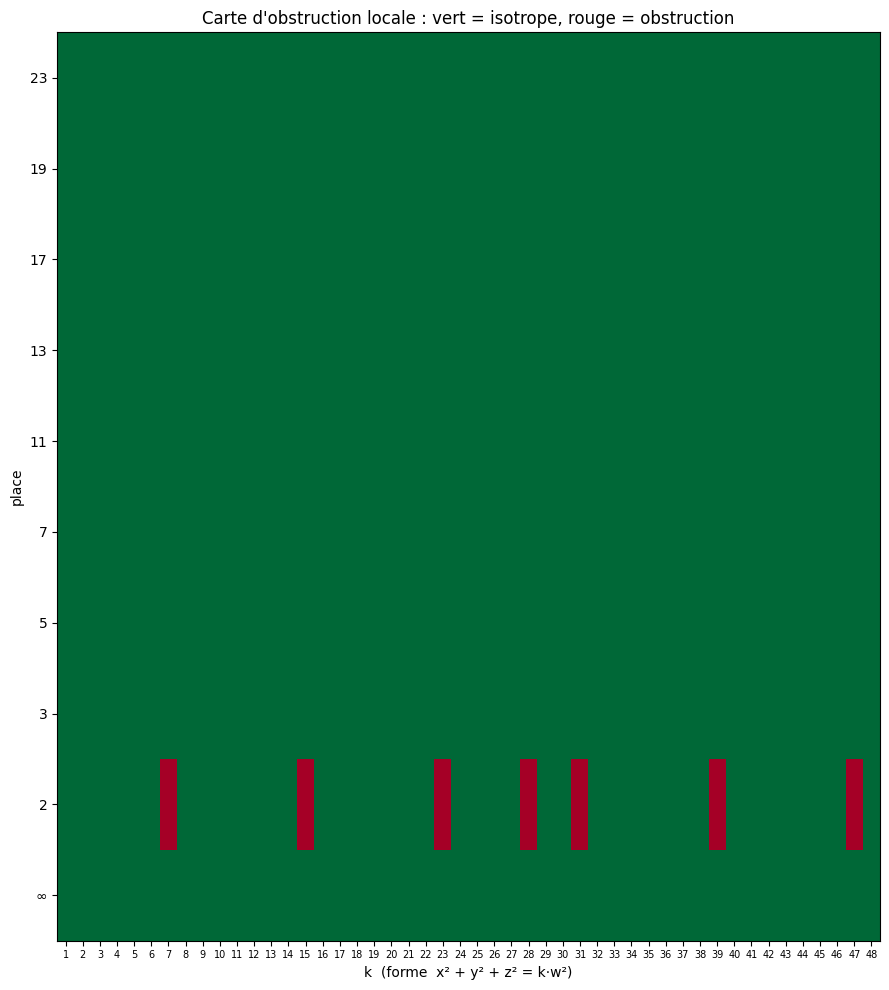

Places rouges vues sur la carte : uniquement la colonne 2, pour k in [7, 15, 23, 28, 31, 39, 47]


In [9]:
import matplotlib.pyplot as plt
import numpy as np

KS = list(range(1, 49))
PLACES_CART = ['inf', 2, 3, 5, 7, 11, 13, 17, 19, 23]

def legendre_trois_carres(k):
    """Critere de Legendre-Gauss : k est somme de 3 carres ssi k != 4^a(8b+7)."""
    while k % 4 == 0:
        k //= 4
    return k % 8 != 7

grille = [[1 if isotrope_local([Fraction(1), Fraction(1), Fraction(1), Fraction(-k)], v) else -1
           for v in PLACES_CART] for k in KS]

acces_local = [all(l == 1 for l in ligne) for ligne in grille]
acces_legendre = [legendre_trois_carres(k) for k in KS]
accord = acces_local == acces_legendre
print("Accord carte locale <-> critere de Legendre-Gauss sur k = 1..48 :", accord)
if accord:
    print("k non sommes de 3 carres, predits par la seule carte locale :",
          [k for k, a in zip(KS, acces_legendre) if not a])

fig, ax = plt.subplots(figsize=(9, 10))
ax.imshow(np.array(grille).T, aspect='auto', cmap='RdYlGn', vmin=-1, vmax=1, origin='lower')
ax.set_xticks(range(len(KS)))
ax.set_xticklabels(KS, fontsize=7)
ax.set_yticks(range(len(PLACES_CART)))
ax.set_yticklabels(['∞'] + [str(p) for p in PLACES_CART[1:]])
ax.set_xlabel("k  (forme  x² + y² + z² = k·w²)")
ax.set_ylabel("place")
ax.set_title("Carte d'obstruction locale : vert = isotrope, rouge = obstruction")
plt.tight_layout()
plt.show()
obst2 = [k for k, ligne in zip(KS, grille) if ligne[1] == -1]
print("Places rouges vues sur la carte : uniquement la colonne 2, pour k in", obst2)

### Lecture de la carte

La colonne $2$ **et elle seule** rougit, uniquement aux $k$ de la forme $4^a(8b+7)$ : $7, 15, 23, 28, 31, 39, 47, \dots$ — les autres places et les autres $k$ restent verts. Le critère de Legendre–Gauss, théorème global de 1798, est **reconstruit par la sonde locale** : la machine ne démontre pas Legendre, elle le **revérifie cas par cas** et en expose la structure — l'obstruction 2-adique $\bmod\ 8$ après extraction des puissances de $4$.

## 9. La limite du principe : la cubique de Selmer

Hasse-Minkowski vit au **degré 2**. Au degré 3, il meurt : **Selmer (1951)** a montré que

$$3x^3 + 4y^3 + 5z^3 = 0$$

possède une solution dans **chaque** $\mathbb{Q}_v$ ($v = \infty$ compris), mais **aucune** solution rationnelle non triviale. Testons le versant local par la force brute, et cherchons — borné — un point rationnel. Nous ne trouverons rien : c'est précisément le théorème.

In [10]:
def cubique_selmer_locale(p, k):
    """3x^3+4y^3+5z^3 = 0 a-t-elle un zero primitif mod p^k ?"""
    m = p ** k
    table = {}
    for z in range(m):
        table.setdefault(-(5 * z ** 3) % m, z)
    for x in range(m):
        cx = 3 * x ** 3 % m
        for y in range(m):
            t = (cx + 4 * y ** 3) % m
            if t in table:
                z = table[t]
                if x % p or y % p or z % p:
                    return True, (x, y, z)
    return False, None

print("Versant local de 3x^3 + 4y^3 + 5z^3 = 0 :")
for p, k in [(2, 3), (3, 2), (5, 2), (7, 2), (11, 2), (13, 2)]:
    ok, temoin = cubique_selmer_locale(p, k)
    print(f"  Q_{p} : zero primitif mod {p}^{k} = {ok}" + (f"  (ex. x,y,z = {temoin})" if ok else ""))
print("  R : evident (forme indefinite, la fonction x |-> -4x^3/3 cubique est surjective sur R)")
print()

# recherche bornee d'un point rationnel : numerateurs |n| <= 20, denominateurs d <= 20
B = 20
pts = sorted({Fraction(n, d) for d in range(1, B + 1) for n in range(-B, B + 1)})
c3 = {Fraction(3) * t ** 3: t for t in pts}
c4 = {Fraction(4) * t ** 3: t for t in pts}
c5 = {Fraction(5) * t ** 3: t for t in pts}
trouve = None
for s1, x in c3.items():
    for s2, y in c4.items():
        if -(s1 + s2) in c5:
            z = c5[-(s1 + s2)]
            if x != 0 or y != 0 or z != 0:
                trouve = (x, y, z)
                break
    if trouve:
        break
print("Recherche bornee (|numerateur| <= 20, denominateur <= 20, ~",
      len(pts) ** 2, "couples) d'un point rationnel : RIEN" if trouve is None else f"trouve {trouve}")
print()
print("Conclusion honnete : la machine confirme le versant local (solutions partout),")
print("ne trouve aucun point rationnel a hauteur bornee, et l'ABSENCE de point rationnel")
print("est le theoreme de Selmer (1951) - cite, non demontre ici.")

Versant local de 3x^3 + 4y^3 + 5z^3 = 0 :
  Q_2 : zero primitif mod 2^3 = True  (ex. x,y,z = (1, 0, 1))
  Q_3 : zero primitif mod 3^2 = True  (ex. x,y,z = (0, 1, 1))
  Q_5 : zero primitif mod 5^2 = True  (ex. x,y,z = (1, 2, 2))
  Q_7 : zero primitif mod 7^2 = True  (ex. x,y,z = (1, 29, 0))
  Q_11 : zero primitif mod 11^2 = True  (ex. x,y,z = (0, 1, 90))
  Q_13 : zero primitif mod 13^2 = True  (ex. x,y,z = (1, 4, 28))
  R : evident (forme indefinite, la fonction x |-> -4x^3/3 cubique est surjective sur R)



Recherche bornee (|numerateur| <= 20, denominateur <= 20, ~ 261121 couples) d'un point rationnel : RIEN

Conclusion honnete : la machine confirme le versant local (solutions partout),
ne trouve aucun point rationnel a hauteur bornee, et l'ABSENCE de point rationnel
est le theoreme de Selmer (1951) - cite, non demontre ici.


## 10. Ce que la machine a prouvé, et ce qu'elle cite

| Affirmation | Statut dans ce carnet |
|---|---|
| valeurs de $(a,b)_v$ (formules de Serre) | **prouvées par accord** avec la force brute $\bmod\ p^k$ (§3) |
| critères d'isotropie locale $n = 2, 3, 4$ | **prouvés par accord** avec la recherche de zéro primitif (§5) |
| formule du produit | **vérifiée** sur table (§4) |
| chaque verdict « isotrope » de la batterie | **prouvé** par un zéro rationnel exhibé et re-vérifié (§6) |
| chaque verdict « anisotrope » | **prouvé** par une place obstructrice calculée (§6) |
| exhaustivité de la liste des places testées | **citée** : c'est le théorème de Hasse-Minkowski |
| théorème des trois carrés (Legendre–Gauss) | **revérifié** sur $k \leq 48$ par la carte locale (§8) |
| absence de point rationnel sur la cubique de Selmer | **citée** : théorème de Selmer 1951 ; versant local vérifié (§9) |

Le versant **preuves formelles** du principe local-global reste ouvert côté dépôt : [08 — Serre dans Mathlib](08-serre-dans-mathlib-Lean.ipynb) et le lake compagnon [`serre100_lean/`](serre100_lean/). L'invariant de Hasse et le théorème 6′ y attendent leur formalisation — piste naturelle pour un pendant kernel.

## Exercices

### Exercice 1 — la table 2-adique par vous-même

La formule $(a,b)_2$ repose sur la table des huit classes d'unités. Écrivez-la directement : pour $a, b \in \{-4, -2, -1, 1, 2, 3\}$, décidez $(a,b)_2$ **par force brute** — résolvez $ax^2 + by^2 \equiv 1 \pmod 8$ — puis comparez à `hilbert(a, b, 2)`.

### Exercice 2 — sommes de trois carrés par décision locale

En utilisant `isotrope_global` (et **sans** le critère de Legendre), listez les $k \leq 100$ qui **ne sont pas** sommes de trois carrés. Vérifiez que votre liste coïncide avec les $k = 4^a(8b+7)$.

### Exercice 3 — des obstructions en nombre pair

Pour la famille ternaire $\langle 1, 1, -k \rangle$ (l'équation $x^2 + y^2 = k z^2$) : trouvez le $k$ le plus petit dont l'ensemble de places obstructrices est exactement $\{2, 3\}$, puis un $k$ dont il est exactement $\{2, 11\}$. Expliquez pourquoi cet ensemble est **toujours de cardinal pair** — le lien se fait dans §4.

In [11]:
# Exercice 1 -- a completer : la table 2-adique par force brute mod 8.
# Indice : S_a = {a x^2 mod 8 : x in 0..7} et S_b = {1 - b y^2 mod 8 : y in 0..7} ;
#          intersection non vide => +1.
# Etape 1 : ecrire table2(a, b) qui decide a x^2 + b y^2 = 1 (mod 8) par balayage.
# Etape 2 : comparer aux valeurs de hilbert(a, b, 2) sur la grille demandee.

def table2(a, b):
    # TODO etudiant
    return None  # TODO etudiant : renvoyer True/False

def exercice1():
    grille = [(-4, -1), (-2, 3), (-1, -1), (-1, 2), (1, 3), (2, 3), (3, 3)]
    attendus = {ab: hilbert(Fraction(ab[0]), Fraction(ab[1]), 2) for ab in grille}
    if table2(-1, 3) is None:
        print("Exercice 1 a completer -- la formule de reference donne par exemple :")
        for ab, s in list(attendus.items())[:4]:
            print(f"  ({ab[0]},{ab[1]})_2 = {s:+d}")
        return None
    return all(table2(a, b) == (s == 1) for (a, b), s in attendus.items())

res1 = exercice1()
print("Exercice 1 :", "ACCORD avec les formules" if res1 else ("a completer" if res1 is None else "ecart detecte"))

Exercice 1 a completer -- la formule de reference donne par exemple :
  (-4,-1)_2 = -1
  (-2,3)_2 = +1
  (-1,-1)_2 = -1
  (-1,2)_2 = +1
Exercice 1 : a completer


In [12]:
# Exercice 2 -- a completer : sommes de trois carres par decision locale.
# Etape 1 : pour k de 1 a 100, former <1,1,1,-k> et demander isotrope_global.
# Etape 2 : extraire les k non sommes de trois carres et comparer aux k = 4^a(8b+7).

def non_sommes_de_trois_carres(limite):
    # TODO etudiant
    return None  # TODO etudiant : liste des k non sommes de 3 carres

if non_sommes_de_trois_carres(10) is None:
    print("Exercice 2 a completer -- indication : la reponse pour k <= 20 commence par [7, 15].")
else:
    predits = non_sommes_de_trois_carres(100)
    attendus = [k for k in range(1, 101) if not legendre_trois_carres(k)]
    print("Exercice 2 :", "ACCORD avec Legendre-Gauss" if predits == attendus else f"ecart : {set(predits) ^ set(attendus)}")

Exercice 2 a completer -- indication : la reponse pour k <= 20 commence par [7, 15].


In [13]:
# Exercice 3 -- a completer : ensembles d'obstructions exacts pour <1,1,-k>.
# Etape 1 : ecrire obstructions_ternaires(k) : la liste des places v ou
#           hilbert(-1, k, v) = -1, pour v dans places_pertinentes(-1, k).
# Etape 2 : chercher les k <= 200 avec ensemble exactement {2, 3}, puis {2, 11}.

def obstructions_ternaires(k):
    # TODO etudiant
    return None  # TODO etudiant

if obstructions_ternaires(3) is None:
    print("Exercice 3 a completer -- indication : l'obstruction en p impair provient du")
    print("facteur (u/p) quand p | k a puissance impaire ; celle en 2 de k mod 8.")
else:
    e23 = [k for k in range(1, 201) if obstructions_ternaires(k) == [2, 3]]
    e211 = [k for k in range(1, 201) if obstructions_ternaires(k) == [2, 11]]
    print("Exercice 3 : k avec obstructions exactement {2,3} :", e23[:6])
    print("             k avec obstructions exactement {2,11} :", e211[:6])

Exercice 3 a completer -- indication : l'obstruction en p impair provient du
facteur (u/p) quand p | k a puissance impaire ; celle en 2 de k mod 8.


## Références

- J.-P. Serre, ***Cours d'arithmétique***, Presses Universitaires de France — ch. II (corps $p$-adiques), ch. III (symbole de Hilbert, formule du produit), ch. IV (formes quadratiques sur $\mathbb{Q}_v$ puis $\mathbb{Q}$ : invariant de Hasse, théorème 6′, Hasse-Minkowski, théorème de Meyer).
- E. S. Selmer, *The Diophantine equation $ax^3 + by^3 + cz^3 = 0$*, Acta Mathematica **85** (1951), 203–362 — le contre-exemple $3x^3+4y^3+5z^3$.
- A. Meyer, *Vierteiljahrsschrift der Naturforschenden Gesellschaft in Zürich* **29** (1884) — le théorème du rang 5.

***

Série [Serre 100](README.md) · En amont : 22 — Vecteurs de Witt, l'arithmétique qui relève Frobenius · Outils : [13 — symboles de Jacobi-Kronecker](13-jacobi-kronecker-reciprocite-II.ipynb) · Versant preuves : [08 — Serre dans Mathlib](08-serre-dans-mathlib-Lean.ipynb). EPIC [#16334](https://github.com/jsboige/CoursIA/issues/16334).